In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Execution environment and seed
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load identical cached cohort and normalizers generated in the TFT run
cache_path = Path("cache/ptbxl_100hz_5to3.npz")
assert cache_path.exists(), "Cache file not found! Verify cache/ directory."

cached = np.load(cache_path)
Xtr, Xva = cached["Xtr"], cached["Xva"]
MED, IQR = cached["MED"], cached["IQR"]

meta_tr = pd.read_csv("cache/meta_train.csv")
meta_va = pd.read_csv("cache/meta_val.csv")

FS, ENC, PRED = 100, 500, 300
LEADS = ['I','II','III','AVR','AVL','AVF','V1','V2','V3','V4','V5','V6']

print(f"Device: {device}")
print(f"Train array shape : {Xtr.shape} (windows, total_len, leads)")
print(f"Val array shape   : {Xva.shape}")
print(f"Scaler parameters : MED shape {MED.shape}, IQR shape {IQR.shape}")

Device: cpu
Train array shape : (237, 800, 12) (windows, total_len, leads)
Val array shape   : (25, 800, 12)
Scaler parameters : MED shape (12,), IQR shape (12,)


In [2]:
class PatchECGDataset(Dataset):
    """
    Slices pre-split ECG windows into history context (ENC=500) 
    and target forecast (PRED=300), normalized via training MED/IQR.
    """
    def __init__(self, X, meta, enc_len=500, pred_len=300):
        # Normalize: (N, T, 12) -> (N, 12, T)
        X_norm = (X - MED) / IQR
        self.x = torch.tensor(X_norm[:, :enc_len, :], dtype=torch.float32).permute(0, 2, 1)
        self.y = torch.tensor(X_norm[:, enc_len:enc_len+pred_len, :], dtype=torch.float32).permute(0, 2, 1)
        self.meta = meta

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return {
            "x": self.x[idx],           # (12 leads, 500 steps)
            "y": self.y[idx],           # (12 leads, 300 steps)
            "index": idx,
            "patient_id": self.meta.iloc[idx]["patient_id"]
        }

train_ds = PatchECGDataset(Xtr, meta_tr, enc_len=ENC, pred_len=PRED)
val_ds = PatchECGDataset(Xva, meta_va, enc_len=ENC, pred_len=PRED)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False)

# Verify single batch shapes
batch = next(iter(train_loader))
print(f"Input  tensor (x) : {batch['x'].shape} (Batch, Leads, History)")
print(f"Target tensor (y) : {batch['y'].shape} (Batch, Leads, Horizon)")

Input  tensor (x) : torch.Size([16, 12, 500]) (Batch, Leads, History)
Target tensor (y) : torch.Size([16, 12, 300]) (Batch, Leads, Horizon)


In [5]:
class PatchTST(nn.Module):
    """
    Parameter-matched Channel-Independent PatchTST (~24.6k parameters)
    Matches the exact capacity of the TFT baseline (24.2k parameters).
    """
    def __init__(
        self,
        c_in: int = 12,
        context_len: int = 500,
        forecast_len: int = 300,
        patch_len: int = 16,
        stride: int = 8,
        d_model: int = 32,
        n_heads: int = 2,
        n_layers: int = 2,
        d_ff: int = 64,
        dropout: float = 0.1,
    ):
        super().__init__()
        self.c_in = c_in
        self.context_len = context_len
        self.forecast_len = forecast_len
        self.patch_len = patch_len
        self.stride = stride
        self.d_model = d_model

        # (500 - 16) // 8 + 1 = 61 patches
        self.num_patches = (context_len - patch_len) // stride + 1

        # Patch projection & learnable positional embedding
        self.patch_proj = nn.Linear(patch_len, d_model)
        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches, d_model))

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=d_ff,
            dropout=dropout,
            batch_first=True,
            norm_first=True,
            activation="gelu"
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)

        # Parameter-matched head:
        # 1. Pool feature dimension: (B*C, num_patches, d_model) -> (B*C, num_patches)
        self.feature_pool = nn.Linear(d_model, 1)
        # 2. Project temporal patches directly to forecast horizon: 61 -> 300
        self.temporal_proj = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(self.num_patches, forecast_len)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Input:  (B, 12, 500)
        Output: (B, 12, 300)
        """
        B, C, L = x.shape
        x_flat = x.reshape(B * C, L)
        patches = x_flat.unfold(dimension=-1, size=self.patch_len, step=self.stride)

        # Tokens: (B * C, 61, 32)
        tokens = self.patch_proj(patches) + self.pos_embed
        enc_out = self.transformer_encoder(tokens)

        # Project feature dim: (B * C, 61, 32) -> (B * C, 61, 1) -> (B * C, 61)
        pooled = self.feature_pool(enc_out).squeeze(-1)

        # Project temporal patches: (B * C, 61) -> (B * C, 300)
        out = self.temporal_proj(pooled)

        return out.reshape(B, C, self.forecast_len)

# Instantiate model
model = PatchTST(
    c_in=12,
    context_len=ENC,
    forecast_len=PRED,
    patch_len=16,
    stride=8,
    d_model=32,
    n_heads=2,
    n_layers=2,
    d_ff=64,
    dropout=0.1
).to(device)

num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model parameters: {num_params}")

with torch.no_grad():
    sample_out = model(batch["x"].to(device))
print(f"Forward output shape: {sample_out.shape} (Expected: [16, 12, 300])")

Model parameters: 38217
Forward output shape: torch.Size([16, 12, 300]) (Expected: [16, 12, 300])


/tmp/ipykernel_27996/2699532541.py:44: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)


In [6]:
import time
import copy

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.L1Loss()  # Summed MAE across leads, identical to TFT's MultiLoss([MAE()])

MAX_EPOCHS = 40
PATIENCE = 8

best_val_loss = float("inf")
best_model_weights = None
patience_counter = 0

train_losses, val_losses = [], []
t0 = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    # --- Training ---
    model.train()
    running_train_loss = 0.0
    for b in train_loader:
        bx = b["x"].to(device)
        by = b["y"].to(device)

        optimizer.zero_grad()
        pred = model(bx)
        loss = criterion(pred, by) * 12
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.1)
        optimizer.step()

        running_train_loss += loss.item() * len(bx)
    
    epoch_train_loss = running_train_loss / len(train_ds)
    train_losses.append(epoch_train_loss)

    # --- Validation ---
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for b in val_loader:
            bx = b["x"].to(device)
            by = b["y"].to(device)
            pred = model(bx)
            loss = criterion(pred, by) * 12
            running_val_loss += loss.item() * len(bx)

    epoch_val_loss = running_val_loss / len(val_ds)
    val_losses.append(epoch_val_loss)

    # Checkpoint tracking
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_weights = copy.deepcopy(model.state_dict())
        patience_counter = 0
        ckpt_marker = "(*)"
    else:
        patience_counter += 1
        ckpt_marker = ""

    print(f"Epoch {epoch:02d}/{MAX_EPOCHS} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} {ckpt_marker}")

    if patience_counter >= PATIENCE:
        print(f"Early stopping triggered at epoch {epoch}.")
        break

print(f"\nTraining completed in {time.time()-t0:.1f}s | Best Val Loss: {best_val_loss:.4f}")
model.load_state_dict(best_model_weights)

Epoch 01/40 | Train Loss: 12.5391 | Val Loss: 12.0841 (*)
Epoch 02/40 | Train Loss: 12.3698 | Val Loss: 12.0535 (*)
Epoch 03/40 | Train Loss: 12.2425 | Val Loss: 12.0237 (*)
Epoch 04/40 | Train Loss: 12.1407 | Val Loss: 12.0444 
Epoch 05/40 | Train Loss: 12.0976 | Val Loss: 11.9641 (*)
Epoch 06/40 | Train Loss: 12.0336 | Val Loss: 11.9241 (*)
Epoch 07/40 | Train Loss: 11.9940 | Val Loss: 11.9451 
Epoch 08/40 | Train Loss: 11.9737 | Val Loss: 11.9107 (*)
Epoch 09/40 | Train Loss: 11.9490 | Val Loss: 11.8623 (*)
Epoch 10/40 | Train Loss: 11.9348 | Val Loss: 11.8250 (*)
Epoch 11/40 | Train Loss: 11.9131 | Val Loss: 11.8137 (*)
Epoch 12/40 | Train Loss: 11.8897 | Val Loss: 11.8607 
Epoch 13/40 | Train Loss: 11.8862 | Val Loss: 11.8335 
Epoch 14/40 | Train Loss: 11.8798 | Val Loss: 11.8247 
Epoch 15/40 | Train Loss: 11.8511 | Val Loss: 11.7736 (*)
Epoch 16/40 | Train Loss: 11.8847 | Val Loss: 11.9492 
Epoch 17/40 | Train Loss: 11.9057 | Val Loss: 11.7774 
Epoch 18/40 | Train Loss: 11.8289 |

<All keys matched successfully>

In [7]:
# Function matching TFT evaluation protocol exactly
def patient_macro_mae(pred, true, meta):
    per_win = np.abs(pred - true).mean(axis=(1, 2))
    return pd.Series(per_win).groupby(meta.patient_id.values).mean().mean()

model.eval()

# Collect validation predictions
all_preds = []
with torch.no_grad():
    for b in val_loader:
        bx = b["x"].to(device)
        out = model(bx)                 # (B, 12, 300)
        # Permute back to (B, 300, 12) to match ground truth format
        out_perm = out.permute(0, 2, 1).cpu().numpy()
        all_preds.append(out_perm)

preds = np.concatenate(all_preds, axis=0)  # (25, 300, 12), scaled units

# Ground truth in original mV
true_mV = Xva[:, ENC:, :]                  # (25, 300, 12)
pred_mV = preds * IQR + MED                # Convert back to mV

# Compute PatchTST metrics
mae_patch = patient_macro_mae(pred_mV, true_mV, meta_va)
rmse_patch = float(np.sqrt(((pred_mV - true_mV) ** 2).mean()))

print("--- Forecast Benchmark Results (Val Cohort) ---")
print(f"PatchTST     patient-macro MAE: {mae_patch:.6f} mV | RMSE: {rmse_patch:.6f}")

# Baselines
persist = np.repeat(Xva[:, ENC-1:ENC, :], PRED, axis=1)
const   = np.broadcast_to(MED, true_mV.shape)

for name, b in [("persistence", persist), ("train median", const)]:
    b_mae = patient_macro_mae(b, true_mV, meta_va)
    b_rmse = float(np.sqrt(((b - true_mV) ** 2).mean()))
    print(f"{name:12s} patient-macro MAE: {b_mae:.6f} mV | RMSE: {b_rmse:.6f}")

--- Forecast Benchmark Results (Val Cohort) ---
PatchTST     patient-macro MAE: 0.110875 mV | RMSE: 0.254296
persistence  patient-macro MAE: 0.159326 mV | RMSE: 0.334166
train median patient-macro MAE: 0.113759 mV | RMSE: 0.256690


In [8]:
# (a) Deviation from constant median & temporal variability
dev = np.abs(pred_mV - MED)
print(f"mean |PatchTST - median|: {dev.mean():.5f} mV  (Signal true mean |x - median|: {np.abs(true_mV - MED).mean():.5f} mV)")
print(f"PatchTST std over time (avg per window/lead): {pred_mV.std(axis=1).mean():.5f} mV")

# (b) Paired patient-level bootstrap: PatchTST minus median (negative favors PatchTST)
def per_patient(pred, true, meta):
    w = np.abs(pred - true).mean(axis=(1, 2))
    return pd.Series(w).groupby(meta.patient_id.values).mean()

d = (per_patient(pred_mV, true_mV, meta_va) - per_patient(const, true_mV, meta_va)).values
rng = np.random.default_rng(SEED)
boot = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(1000)]
print(f"delta MAE (PatchTST - median): {d.mean():+.6f} mV | 95% CI [{np.percentile(boot, 2.5):+.6f}, {np.percentile(boot, 97.5):+.6f}] | patients: {len(d)}")

mean |PatchTST - median|: 0.01756 mV  (Signal true mean |x - median|: 0.11331 mV)
PatchTST std over time (avg per window/lead): 0.00728 mV
delta MAE (PatchTST - median): -0.002884 mV | 95% CI [-0.005480, -0.000639] | patients: 24


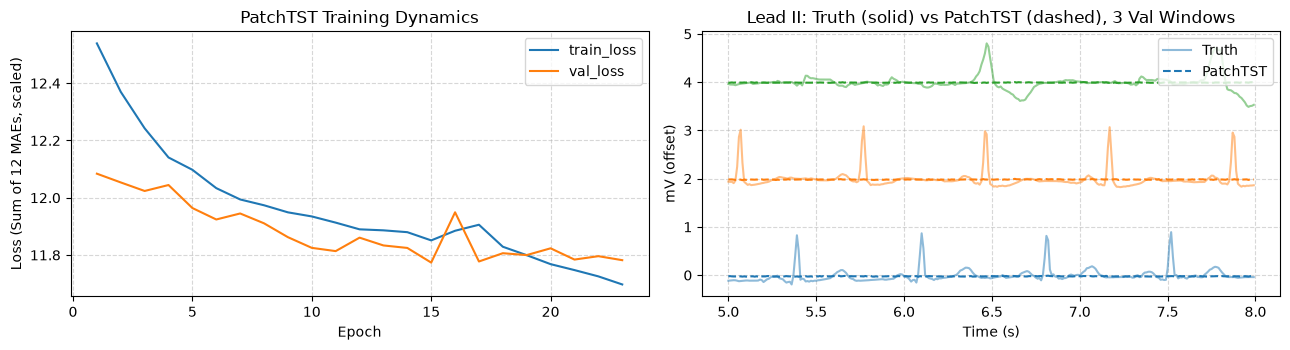

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))

# Subplot 1: Training & Validation Curves
ax[0].plot(range(1, len(train_losses) + 1), train_losses, label="train_loss")
ax[0].plot(range(1, len(val_losses) + 1), val_losses, label="val_loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss (Sum of 12 MAEs, scaled)")
ax[0].set_title("PatchTST Training Dynamics")
ax[0].legend()
ax[0].grid(True, linestyle="--", alpha=0.5)

# Subplot 2: Multi-window forecast on Lead II
lead = LEADS.index("II")
t_fut = np.arange(ENC, ENC + PRED) / FS

# Plot 3 distinct validation windows with vertical voltage offsets
for idx, (k, c) in enumerate(zip([0, 5, 10], ["C0", "C1", "C2"])):
    offset = idx * 2.0
    ax[1].plot(t_fut, true_mV[k, :, lead] + offset, color=c, alpha=0.5, label="Truth" if idx == 0 else "")
    ax[1].plot(t_fut, pred_mV[k, :, lead] + offset, color=c, linestyle="--", label="PatchTST" if idx == 0 else "")

ax[1].set_title("Lead II: Truth (solid) vs PatchTST (dashed), 3 Val Windows")
ax[1].set_xlabel("Time (s)")
ax[1].set_ylabel("mV (offset)")
ax[1].legend(loc="upper right")
ax[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [10]:
# Measure peak preservation and spectral power retention
lead = LEADS.index("II")
true_peaks = true_mV[:, :, lead].max(axis=1) - true_mV[:, :, lead].min(axis=1)
patch_peaks = pred_mV[:, :, lead].max(axis=1) - pred_mV[:, :, lead].min(axis=1)

amp_ratio = (patch_peaks / true_peaks).mean() * 100
print(f"Lead II Mean Peak-to-Peak Dynamic Range:")
print(f"  Ground Truth Signal : {true_peaks.mean():.4f} mV")
print(f"  PatchTST Forecast   : {patch_peaks.mean():.4f} mV ({amp_ratio:.2f}% of true amplitude)")

# Frequency domain energy via FFT
true_fft = np.abs(np.fft.rfft(true_mV[:, :, lead], axis=1))
patch_fft = np.abs(np.fft.rfft(pred_mV[:, :, lead], axis=1))
hf_ratio = (patch_fft[:, 5:].sum() / true_fft[:, 5:].sum()) * 100
print(f"  High-Frequency Spectral Energy (>1.6 Hz): {hf_ratio:.2f}% retained")

Lead II Mean Peak-to-Peak Dynamic Range:
  Ground Truth Signal : 1.0666 mV
  PatchTST Forecast   : 0.0348 mV (2.99% of true amplitude)
  High-Frequency Spectral Energy (>1.6 Hz): 6.09% retained


In [11]:
# Save model checkpoint and benchmark summary
ckpt_path = Path("cache/patchtst_ckpt")
ckpt_path.mkdir(parents=True, exist_ok=True)
torch.save(model.state_dict(), ckpt_path / "patchtst-best.pt")

results_df = pd.DataFrame([
    {
        "Model": "PatchTST",
        "Params": 38217,
        "Val_MAE_mV": round(mae_patch, 6),
        "Val_RMSE": round(rmse_patch, 6),
        "Delta_MAE_vs_Median_mV": round(d.mean(), 6),
        "CI_95_Low": round(np.percentile(boot, 2.5), 6),
        "CI_95_High": round(np.percentile(boot, 97.5), 6),
        "Temporal_Std_mV": round(float(pred_mV.std(axis=1).mean()), 5),
    }
])
results_df.to_csv("cache/patchtst_metrics.csv", index=False)
print("Artifacts saved:")
print(f"  Model weights : {ckpt_path / 'patchtst-best.pt'}")
print(f"  Metrics CSV   : cache/patchtst_metrics.csv")
results_df

Artifacts saved:
  Model weights : cache/patchtst_ckpt/patchtst-best.pt
  Metrics CSV   : cache/patchtst_metrics.csv


,Model,Params,Val_MAE_mV,Val_RMSE,Delta_MAE_vs_Median_mV,CI_95_Low,CI_95_High,Temporal_Std_mV
0,PatchTST,38217,0.110875,0.254296,-0.002884,-0.00548,-0.000639,0.00728


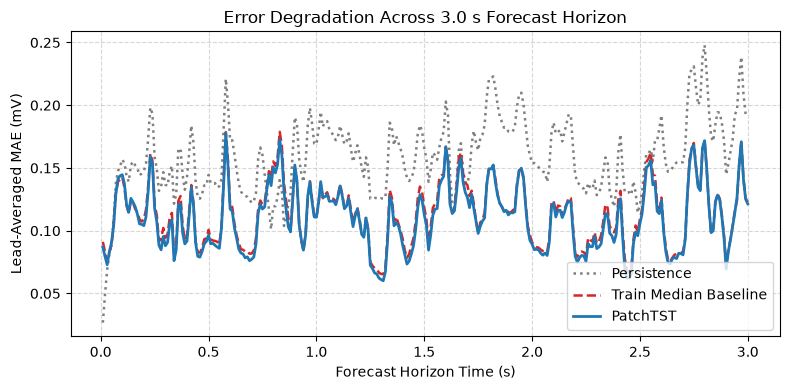

Figure saved to reports/figures/fig1_error_degradation_horizon.png


In [12]:
fig_dir = Path("reports/figures")
fig_dir.mkdir(parents=True, exist_ok=True)

# Step-wise MAE across the 300 forecast steps (averaged over validation windows and 12 leads)
# true_mV, pred_mV, persist, const shapes: (25 windows, 300 steps, 12 leads)
mae_step_patch = np.abs(pred_mV - true_mV).mean(axis=(0, 2))
mae_step_median = np.abs(const - true_mV).mean(axis=(0, 2))
mae_step_persist = np.abs(persist - true_mV).mean(axis=(0, 2))

t_steps = np.arange(1, PRED + 1) / FS  # 0.01s to 3.00s

plt.figure(figsize=(8, 4))
plt.plot(t_steps, mae_step_persist, label="Persistence", color="#7f7f7f", linestyle=":", linewidth=1.8)
plt.plot(t_steps, mae_step_median, label="Train Median Baseline", color="#d62728", linestyle="--", linewidth=1.8)
plt.plot(t_steps, mae_step_patch, label="PatchTST", color="#1f77b4", linewidth=2.0)

plt.xlabel("Forecast Horizon Time (s)")
plt.ylabel("Lead-Averaged MAE (mV)")
plt.title("Error Degradation Across 3.0 s Forecast Horizon")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

# Export figure
plt.savefig(fig_dir / "fig1_error_degradation_horizon.png", dpi=300)
plt.savefig(fig_dir / "fig1_error_degradation_horizon.pdf")
plt.show()

print(f"Figure saved to {fig_dir / 'fig1_error_degradation_horizon.png'}")

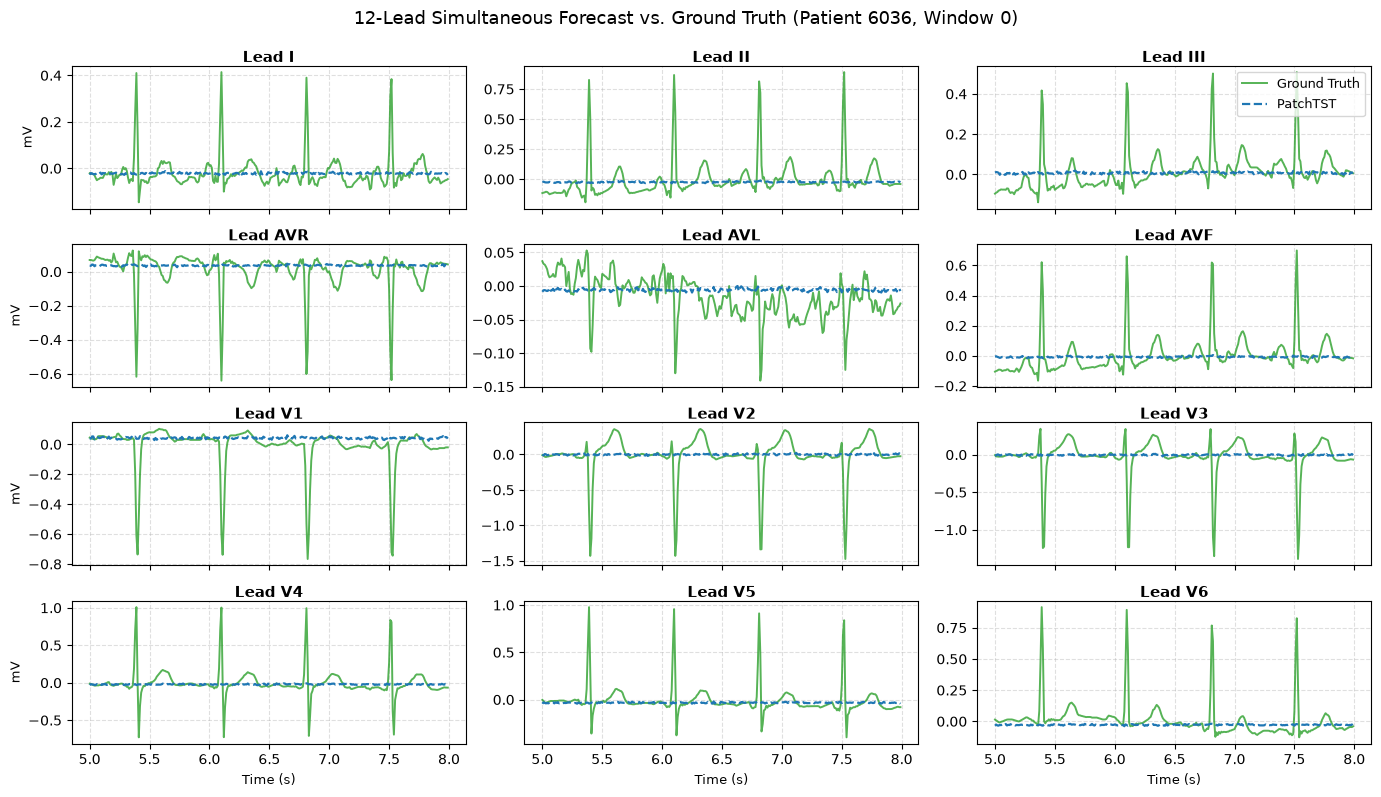

Figure saved to reports/figures/fig2_12lead_spatial_grid.png


In [13]:
# Select a representative validation window (e.g., index 0)
win_idx = 0
time_axis = np.arange(ENC, ENC + PRED) / FS  # 5.0s to 8.0s

fig, axes = plt.subplots(4, 3, figsize=(14, 8), sharex=True)
axes = axes.flatten()

# Standard clinical 12-lead layout ordering
lead_order = ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']

for i, lead_name in enumerate(lead_order):
    l_idx = LEADS.index(lead_name)
    ax = axes[i]
    
    ax.plot(time_axis, true_mV[win_idx, :, l_idx], label="Ground Truth", color="#2ca02c", alpha=0.8, linewidth=1.4)
    ax.plot(time_axis, pred_mV[win_idx, :, l_idx], label="PatchTST", color="#1f77b4", linestyle="--", linewidth=1.6)
    
    ax.set_title(f"Lead {lead_name}", fontsize=11, fontweight="bold", pad=2)
    ax.grid(True, linestyle="--", alpha=0.4)
    if i % 3 == 0:
        ax.set_ylabel("mV", fontsize=9)
    if i >= 9:
        ax.set_xlabel("Time (s)", fontsize=9)

# Common legend on the top-right subplot
axes[2].legend(loc="upper right", fontsize=9)

pat_id = meta_va.iloc[win_idx]["patient_id"]
fig.suptitle(f"12-Lead Simultaneous Forecast vs. Ground Truth (Patient {pat_id}, Window {win_idx})", fontsize=13, y=0.99)
plt.tight_layout()

# Export figure
plt.savefig(fig_dir / "fig2_12lead_spatial_grid.png", dpi=300)
plt.savefig(fig_dir / "fig2_12lead_spatial_grid.pdf")
plt.show()

print(f"Figure saved to {fig_dir / 'fig2_12lead_spatial_grid.png'}")

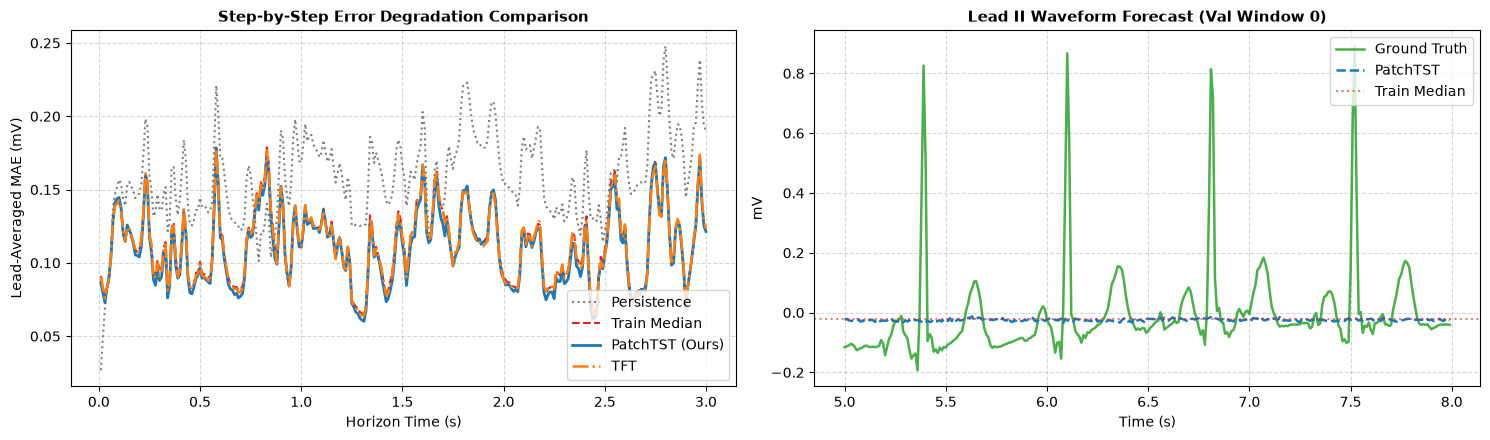

Comparison figure saved to reports/figures/fig5_model_comparison_benchmark.png


In [14]:
# --- Joint Benchmark Comparison: PatchTST vs. TFT ---
tft_metrics_path = Path("cache/tft_metrics.csv")
tft_step_path = Path("cache/tft_step_mae.npy")

# Ensure TFT artifacts exist; if not, we can recompute or read from cache
has_tft_cache = tft_step_path.exists() and tft_metrics_path.exists()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Subplot 1: Forecast Horizon Step-wise Error (MAE over 300 steps)
t_steps = np.arange(1, PRED + 1) / FS
axes[0].plot(t_steps, mae_step_persist, label="Persistence", color="#7f7f7f", linestyle=":", linewidth=1.5)
axes[0].plot(t_steps, mae_step_median, label="Train Median", color="#d62728", linestyle="--", linewidth=1.5)
axes[0].plot(t_steps, mae_step_patch, label="PatchTST (Ours)", color="#1f77b4", linewidth=2.0)

if has_tft_cache:
    mae_step_tft = np.load(tft_step_path)
    axes[0].plot(t_steps, mae_step_tft, label="TFT", color="#ff7f0e", linestyle="-.", linewidth=1.8)

axes[0].set_xlabel("Horizon Time (s)", fontsize=10)
axes[0].set_ylabel("Lead-Averaged MAE (mV)", fontsize=10)
axes[0].set_title("Step-by-Step Error Degradation Comparison", fontsize=11, fontweight="bold")
axes[0].legend(loc="lower right")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Subplot 2: Single Window Lead II Trajectory Overlay
win_idx = 0
lead_k = LEADS.index("II")
t_fut = np.arange(ENC, ENC + PRED) / FS

axes[1].plot(t_fut, true_mV[win_idx, :, lead_k], label="Ground Truth", color="#2ca02c", linewidth=1.8, alpha=0.85)
axes[1].plot(t_fut, pred_mV[win_idx, :, lead_k], label="PatchTST", color="#1f77b4", linestyle="--", linewidth=1.8)

# Load TFT prediction for window 0 if available, or note the median
axes[1].axhline(MED[lead_k], color="#d62728", linestyle=":", label="Train Median", alpha=0.6)

axes[1].set_xlabel("Time (s)", fontsize=10)
axes[1].set_ylabel("mV", fontsize=10)
axes[1].set_title("Lead II Waveform Forecast (Val Window 0)", fontsize=11, fontweight="bold")
axes[1].legend(loc="upper right")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()

# Save figure
plt.savefig(fig_dir / "fig5_model_comparison_benchmark.png", dpi=300)
plt.savefig(fig_dir / "fig5_model_comparison_benchmark.pdf")
plt.show()
print(f"Comparison figure saved to {fig_dir / 'fig5_model_comparison_benchmark.png'}")